# Reproducing Figure 1 of *Understanding Deep Learning Requires Rethinking Generalization* (Zhang et al., ICLR 2017) in PyTorch

Figure 1 ("Fitting random labels and random pixels on CIFAR10") has three panels:

* **(a) learning curves**: training loss of the small Inception vs. thousand steps for true labels, random labels, shuffled pixels, random pixels and Gaussian inputs;
* **(b) convergence slowdown**: time to overfit, relative to clean labels, vs. label corruption for Inception, AlexNet and MLP 1x512;
* **(c) generalization error growth**: test error after convergence vs. label corruption, with chance level (0.9) dashed.

Everything below is written from the paper alone. Choices the paper makes are cited (Sec. / App. / Table / Fig.); choices it leaves open are numbered **U1–U22** and listed together in Section 3; the convergence-time definition for Fig. 1b is in Section 4; the compute plan is in Section 5.

**Requirements:** `torch`, `torchvision` (only for the CIFAR10 download), `numpy`, `pandas`, `matplotlib`.

**How to use**

1. Set `SMOKE_TEST = True` and *Run All*. This uses a small synthetic dataset and tiny schedules, takes a few minutes, exercises every code path (including checkpoint/resume), and writes a meaningless Figure 1 to `results_fig1_smoke/`.
2. Set `SMOKE_TEST = False` and *Run All*. CIFAR10 is downloaded to `./data`; the notebook benchmarks the GPU, projects the cost of the plan against `GPU_BUDGET_HOURS`, then runs the queue in priority order.
3. If anything stops (Ctrl-C, kernel restart, budget exhausted), *Run All* again. Finished runs are skipped and unfinished runs resume from their last checkpoint. With `DETERMINISTIC = True` the continuation is bitwise identical to an uninterrupted run (checked in Section 10). `figures/figure1.png` is rebuilt after every run, so a usable figure exists as soon as phase 1 is done.

**Files written** (under `results_fig1/`)

| path | content |
|---|---|
| `runs/<run_id>/config.json` | every setting of the run, resolved |
| `runs/<run_id>/train_labels.npy` | the exact (possibly corrupted) training labels used |
| `runs/<run_id>/losses.f32` | training mini-batch loss of every SGD step (raw float32) |
| `runs/<run_id>/evals.jsonl` | full train / test accuracy and loss at step 0 and every evaluation |
| `runs/<run_id>/status.json`, `checkpoint.pt` | progress and resumable state |
| `derived/fig1a_curves.csv`, `derived/fig1bc_points.csv` | every plotted number, computed from the logs above |
| `figures/figure1.{png,pdf}` + 2 supplementary figures | built only from the two CSV files |

## 1. Setup

In [1]:
import os
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")   # deterministic cuBLAS; must be set before CUDA initializes

import json, math, time, shutil
from dataclasses import dataclass, asdict
from pathlib import Path
from typing import Optional

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib
import matplotlib.pyplot as plt

# ---------------- switches ----------------
SMOKE_TEST       = False       # True: synthetic data + tiny schedules; validates every code path in a few minutes
GPU_BUDGET_HOURS = 7.0         # covers benchmark + self-test + all training runs; tracked on disk across restarts
RUN_PHASES       = (1, 2, 3)   # Section 5; (1, 2) gives the reduced set {0, 0.2, ..., 1.0}
DETERMINISTIC    = False        # bitwise-repeatable kernels (verified in Section 10); False is faster
USE_AMP          = True        # fp16 autocast + dynamic loss scaling on GPU (U19)
CHANNELS_LAST    = True        # NHWC layout for conv nets (speed only)
RUN_SELF_TEST    = True
DATA_DIR         = Path("data")
RESULTS_DIR      = Path("results_fig1_smoke" if SMOKE_TEST else "results_fig1")

In [2]:
# Experimental constants.  App./Sec./Table/Fig. = the paper;  U# = unspecified choice (Section 3)
NUM_CLASSES = 10                          # CIFAR10 (App. A)
IMG, CROP = 32, 28                        # App. A: 32x32 images, centre crop to 28x28
MODELS = ("inception", "alexnet", "mlp1x512")                  # Fig. 1b/1c legend
LR0 = {"inception": 0.1, "alexnet": 0.01, "mlp1x512": 0.01}    # App. A
MOMENTUM = 0.9                            # App. A
LR_DECAY_PER_EPOCH = 0.95                 # App. A; applied as a per-epoch staircase (U2)
WEIGHT_DECAY = 0.0                        # App. A: no weight decay, dropout or other explicit regularization (U9)
BATCH_SIZE = 128                          # U1
MAX_EPOCHS = 80                           # U3: cap; the LR is then 0.95**80 = 1.7% of its initial value
FIG1A_STEPS = 25_000                      # Fig. 1a x-axis: 0-25 thousand steps
CONV_TAU = 0.99                           # Section 4: training accuracy that defines "converged" for Fig. 1b
SENS_TAUS = (0.95, 0.99, 0.999)           # Section 4: Fig. 1b recomputed at other thresholds (supplementary)
STOP_TRAIN_ACC = 0.999                    # U3, U14: a run ends at the first evaluation with >= 99.9% train accuracy
EVAL_EVERY = 200                          # U16: full train + test evaluation every 200 steps (and at step 0)
FIG1A_ONLY_EVAL_EVERY = 1000              # U16: the 3 input-randomization runs only need their loss curve
CKPT_EVERY = 2000                         # checkpoint period in steps (also at every pause and at the end)
EVAL_BATCH = 2000                         # inference batch size (does not affect results)
LOSS_WINDOW = 500                         # U10: Fig. 1a "average_loss" = mean mini-batch loss over 500-step windows
LEVELS_ALL = [round(0.1 * k, 1) for k in range(11)]   # Fig. 1b/1c markers: 0.0, 0.1, ..., 1.0
SEED, DATA_SEED = 0, 0                    # U18

if SMOKE_TEST:                            # tiny versions of everything: numbers are meaningless, code paths identical
    BATCH_SIZE, MAX_EPOCHS, FIG1A_STEPS = 64, 3, 24
    EVAL_EVERY = FIG1A_ONLY_EVAL_EVERY = CKPT_EVERY = 8
    EVAL_BATCH, LOSS_WINDOW = 256, 4
    LEVELS_ALL = [0.0, 0.2, 0.5, 1.0]
    SMOKE_N_TRAIN, SMOKE_N_TEST = 512, 256

In [3]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP_ON = USE_AMP and DEVICE.type == "cuda"
if DEVICE.type != "cuda" and not SMOKE_TEST:
    print("WARNING: no CUDA device. The full experiment needs a GPU; set SMOKE_TEST = True to test the pipeline.")

torch.backends.cudnn.benchmark = not DETERMINISTIC           # autotuning picks kernels by timing -> not repeatable
torch.backends.cudnn.deterministic = DETERMINISTIC
torch.use_deterministic_algorithms(DETERMINISTIC, warn_only=True)   # Section 10 checks bitwise equality empirically
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True

RUNS_DIR, DERIVED_DIR, FIG_DIR = RESULTS_DIR / "runs", RESULTS_DIR / "derived", RESULTS_DIR / "figures"
for _d in (RUNS_DIR, DERIVED_DIR, FIG_DIR, DATA_DIR):
    _d.mkdir(parents=True, exist_ok=True)

# Each source of randomness has its own seed derived from (purpose, ...), so e.g. the corrupted labels do not depend
# on the model and the batch order does not depend on the corruption level (U18).
SEED_LABELS, SEED_INPUTS, SEED_ORDER, SEED_INIT = 1, 2, 3, 4
def derive_seed(*keys) -> int:
    return int(np.random.SeedSequence([int(k) for k in keys]).generate_state(1)[0])

def read_json(path):
    path = Path(path)
    return json.loads(path.read_text()) if path.exists() else None

def write_json(path, obj):                    # atomic write: never leaves a half-written file
    path = Path(path)
    tmp = path.with_name(path.name + ".tmp")
    tmp.write_text(json.dumps(obj, indent=2))
    os.replace(tmp, path)

def sync():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

print(f"torch {torch.__version__} | {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else "")
      + f" | AMP {AMP_ON} | deterministic {DETERMINISTIC} | results -> {RESULTS_DIR.resolve()}")

torch 2.14.1+cu130 | cuda (NVIDIA GeForce RTX 3080 Ti) | AMP True | deterministic False | results -> C:\Users\Tyler\Documents\AML Assignment 2 Reproduce\results_fig1


## 2. What the paper specifies, and where

| Item | Implementation | Source |
|---|---|---|
| Data | CIFAR10, 50,000 training and 10,000 held-out ("validation") images, 10 classes | App. A |
| Preprocessing | ÷255 → central 28×28 crop → per-image whitening: subtract the image mean, divide by max(std, 1/√2352) (TensorFlow `per_image_whitening`) | App. A |
| Networks in Fig. 1 | small Inception in (a); small Inception, small AlexNet and MLP 1x512 in (b) and (c) | Fig. 1 legends, Sec. 2.1, App. A |
| Small Inception | Conv module = conv → BN → ReLU; Inception module = 1×1 branch ‖ 3×3 branch; Downsample = 3×3 stride-2 conv ‖ 3×3 stride-2 max-pool; module list and widths as drawn; global 7×7 mean pooling; 10-way fully connected | Fig. 3 |
| Small AlexNet | two (5×5 conv → 3×3 max-pool → LRN) modules, FC 384, FC 192, 10-way linear | App. A |
| MLP 1x512 | one hidden layer of 512 units | App. A |
| Activations | ReLU everywhere | App. A |
| Parameter counts | 1,649,402 / 1,387,786 / 1,209,866, **asserted exactly** in Section 7 | Table 1 |
| Optimizer | SGD with momentum 0.9 | App. A |
| Learning rate | 0.1 (Inception), 0.01 (AlexNet, MLP), × 0.95 per epoch | App. A |
| Regularization | none: no weight decay, dropout, data augmentation | App. A; Sec. 2.1 ("unchanged hyperparameter settings") |
| Label corruption | independently with probability p, a training label is replaced by a uniform random class; p = 1 is "random labels"; labels fixed across epochs | Sec. 2.1 |
| Input randomizations | shuffled pixels (one permutation, train and test), random pixels (independent permutation per image), Gaussian (dataset mean and variance) | Sec. 2.1 |
| Corruption levels | 0.0, 0.1, …, 1.0 (marker positions) | Fig. 1b, 1c |
| Fig. 1a | training loss, 0–25k steps, Inception on CIFAR10 | Fig. 1a, Sec. 2.1 |
| Fig. 1b | convergence time relative to the clean-label run | Fig. 1 caption ("relative convergence time") |
| Fig. 1c | test error after convergence; equals generalization error because training error ≈ 0; chance = 0.9 | Fig. 1c, Sec. 2.1 |

## 3. Unspecified details and the choices made (all in one place)

| # | Not specified in the paper | Choice | Reasoning |
|---|---|---|---|
| U1 | batch size | **128** | Plausibility check against Fig. 1a's step axis: at 391 steps/epoch, the true-label loss reaching ≈0 near 5k steps is ≈13 epochs and the random-label fit at 15–19k steps is ≈40–50 epochs, when the LR is still 8–13% of its initial value. Batch 32 would mean zero true-label loss after ~3 epochs; batch ≥256 would put the random-label fit after the LR has decayed below ~2%. This is a consistency argument, not a derivation. |
| U2 | how "0.95 per epoch" is applied | staircase: `lr = lr0 · 0.95^epoch` | literal reading of "per training epoch" |
| U3 | training length | stop at the first evaluation with ≥ 99.9% training accuracy; hard cap of 80 epochs (31,280 steps); runs used in Fig. 1a train ≥ 25k steps, the three input-randomization runs exactly 25k | Sec. 2.1 says the corrupted training sets are fit perfectly, so runs go until (essentially) zero training error. At epoch 80 the LR is 0.95⁸⁰ ≈ 1.7% of its initial value and only ≈1.7% of the schedule's total step size Σ0.95ᵉ is left, so a run that has not fit by then effectively never will. |
| U4 | weight initialization | Glorot/Xavier-uniform weights, zero biases | TensorFlow's default initializer; the paper used TensorFlow (App. A) |
| U5 | BatchNorm details | conv layers have no bias; BN learns a per-channel shift β, scale γ fixed at 1; momentum 0.1, ε = 1e-5 (PyTorch defaults); running statistics at evaluation | Table 1's 1,649,402 = conv weights (1,644,320) + one value per BN channel (1,712) + FC (3,370) exactly. "Inception w/o BatchNorm" has the same count, so that per-channel value is a bias in both variants. This matches TensorFlow's `batch_norm` default (center=True, scale=False). |
| U6 | padding | "same" padding (k//2) for every conv and pool | required for Fig. 3's 28→14→7 resolution and 7×7 global pooling, and for AlexNet's parameter count. PyTorch pads symmetrically, whereas TensorFlow's SAME puts the extra row/column at bottom/right for stride 2: a one-pixel alignment difference. |
| U7 | AlexNet widths and LRN | 64 filters per conv, max-pool stride 2; LRN with n = 5, k = 2, α = 1e-4, β = 0.75; ReLU after each conv, before pooling | 64/64 with stride-2 pooling is the only integer solution that gives Table 1's 1,387,786. LRN constants are those of Krizhevsky et al. (2012), the paper's AlexNet reference. |
| U8 | loss | mean softmax cross-entropy | Fig. 1a curves start at ≈2.3 = ln 10 |
| U9 | regularization for p = 0 | none, like every other Fig. 1 run | App. A only says this for randomized runs, but Fig. 1 compares corruption levels at fixed hyperparameters, and Table 1's unregularized test accuracies (Inception 85.75%, AlexNet 76.07%, MLP 50.51%) are consistent with Fig. 1c's values at p = 0 |
| U10 | "average_loss" in Fig. 1a | mean training mini-batch loss over consecutive 500-step windows, plotted at window centres | the paper's smoothing is not described |
| U11 | label-corruption details | the replacement class is uniform over all 10 classes, so it can equal the true class (≈0.9·p of labels actually change); the random draws are shared by all p and all models, so corrupted sets are nested in p and identical across models; test labels are never corrupted | literal reading of Sec. 2.1; coupling across p removes label-sampling noise from the p-dependence |
| U12 | what a "pixel" is when shuffling | a spatial position of the 28×28 crop; its three channel values move together; done before whitening | whitening is permutation-invariant, so the order does not matter |
| U13 | Gaussian inputs, and labels/test sets of the input-randomization runs | i.i.d. Gaussian pixels with the per-channel mean and variance of the cropped [0,1] training images, then whitened like any image; original labels kept; test sets get the same treatment (fresh per-image permutations / fresh noise) | Sec. 2.1 lists these as input changes only. For Gaussian inputs the labels carry no information either way. Their test numbers are logged but not used in Fig. 1. |
| U14 | when Fig. 1c's test error is measured | at the first evaluation with ≥ 99.9% training accuracy (when the run stops); if never reached, at the end of the run (drawn hollow) | "test errors after convergence" with training error ≈ 0 (Sec. 2.1). The two Inception runs that continue to 25k steps for Fig. 1a are read at that same moment from their logs. |
| U15 | how convergence time is measured | see **Section 4** | |
| U16 | evaluation protocol | full passes over all 50k training and 10k test images in eval mode at step 0 and every 200 steps (every 1000 steps for the three input-randomization runs) | needed for U14 and Section 4 |
| U17 | epochs and data order | reshuffle every epoch; the last batch of 80 images is kept (391 steps per epoch); order is a function of (seed, epoch) only | every example is seen once per epoch; resume needs no stored generator state |
| U18 | seeds and replicates | one seed per configuration, as the paper shows single runs; the same initial weights for all p of a model and the same batch order for every run | common random numbers make the p-dependence less noisy; the budget does not allow replicates |
| U19 | numerical precision | fp16 autocast with dynamic loss scaling, TF32, channels-last (`USE_AMP`) | compute budget. The paper presumably used fp32; set `USE_AMP = False` to match at roughly 2× the cost. |
| U20 | momentum form | v ← μv + g, w ← w − ηv | PyTorch SGD; identical to TensorFlow's MomentumOptimizer |
| U21 | test split | CIFAR10's official 10,000-image test set with true labels | App. A's "10,000 validation images" |
| U22 | Fig. 1b normalization | T(p)/T(0) of the same architecture | Fig. 1b's y-axis is 1 at p = 0; caption: "relative convergence time" |

## 4. How convergence time (Fig. 1b) is measured, and why

**Definition.** For a run at corruption level p, let acc(t) be the fraction of the 50,000 training images whose predicted class (argmax of the logits) equals the label *the network is trained on*, i.e. the corrupted label. It is computed with a full pass over the training set in eval mode (BatchNorm uses running statistics, no parameter updates) at step 0 and every 200 SGD steps. With τ = 0.99, the convergence time T(p) is the first step at which acc(t) ≥ τ, located by linear interpolation between the last evaluation below τ, (t₀, a₀), and the first at or above it, (t₁, a₁):

  T(p) = t₀ + (τ − a₀)/(a₁ − a₀) · (t₁ − t₀).

A step is one SGD update on a mini-batch of 128. Fig. 1b plots **T(p)/T(0)** for each architecture, where both runs share the same initial weights and batch order.

**Why this definition.**

* *Training accuracy against the training labels*, because "time to overfit" means time to fit the (corrupted) training set, and the paper measures fitting by training accuracy (Table 1; Sec. 2.1, "the networks fit the corrupted training set perfectly"). A loss threshold would mix fitting with how confident the predictions are, and its meaning shifts with p.
* *τ = 0.99 rather than 100%*, because Table 1 reports AlexNet and MLP 1x512 ending at 99.82% and 99.34% on random labels, so a 100% criterion would be undefined for curves the paper does plot. 99% is below every final training accuracy in Table 1 for these three models but still demanding: at p = 1, about 90% of labels disagree with the image's true class, and 99% accuracy requires reproducing at least ≈98.9% of those arbitrary labels.
* *A full eval-mode pass rather than the running mini-batch accuracy*, because the running average is computed with weights that change during the epoch and with batch statistics, so it lags the network's actual state by up to an epoch. That lag is a larger fraction of T for fast-converging runs, which would bias the ratios.
* *Linear interpolation*, because with evaluations 200 steps apart the raw first-crossing step can be off by up to 200 steps, a few percent of T(0); interpolation removes most of that.
* *Steps rather than wall-clock time*, because steps are hardware-independent and every run uses the same batch size, so steps are proportional to examples processed. The ratio removes the units anyway.
* *Robustness check*: the same logs give T at τ ∈ {0.95, 0.99, 0.999}; a supplementary figure plots Fig. 1b for all three, so you can see whether conclusions depend on τ.
* *Runs that never reach τ* before the 80-epoch cap are drawn as hollow ▲ at (cap)/T(0): a lower bound, not a measurement.

## 5. Compute plan and run order

**Runs needed.** Fig. 1a needs five Inception runs; the "true labels" and "random labels" curves are the same runs as Inception's p = 0 and p = 1 points in Fig. 1b/1c. Fig. 1b/1c need 3 models × 11 levels = 33 runs. Total: **36 runs**.

**Order** (each phase leaves a complete figure behind):

| phase | runs | what you have after it |
|---|---|---|
| 1 | Inception p = 0 and 1 (≥25k steps, also Fig. 1a); MLP and AlexNet p = 0 and 1; Inception shuffled / random pixels / Gaussian (25k steps each) | complete Fig. 1a; endpoints of Fig. 1b/1c for all three models |
| 2 | p = 0.2, 0.4, 0.6, 0.8 for each model (MLP, AlexNet, Inception) | Fig. 1b/1c at 6 levels |
| 3 | p = 0.1, 0.3, 0.5, 0.7, 0.9 for each model | full 11 levels |

**Rough a-priori cost** (Section 11 replaces this with measured numbers). Forward cost per image: Inception ≈ 0.20 GMAC, AlexNet ≈ 0.025 GMAC, MLP ≈ 0.001 GMAC. On an RTX 3080 Ti with fp16 autocast I expect roughly 8–15 ms per Inception step at batch 128, a few ms for AlexNet, ~1 ms for the MLP (kernel-launch bound), and ~1 s per full Inception evaluation of 60k images. In the **worst case**, where every run hits the 80-epoch cap, that gives Inception ≈ 7–10 min per run × 11 plus ≈ 4–7 min × 3 fixed-length runs (≈ 1.4–2.2 h), AlexNet ≈ 2 min × 11 (≈ 0.4 h) and MLP ≈ 0.6 min × 11 (≈ 0.1 h), for a total of **≈ 1.9–2.8 GPU-hours**. Runs normally stop well before the cap, at 99.9% training accuracy. The full 11-level set is therefore planned, but the margin is thin, so:

* the queue tracks GPU time on disk and pauses cleanly (with a checkpoint) when `GPU_BUDGET_HOURS` is used up;
* Section 11 prints the projected worst-case cost per phase from measured throughput before anything is trained;
* **fallback (reduced set): phases 1 + 2**, i.e. levels {0, 0.2, 0.4, 0.6, 0.8, 1.0} for all three models plus all of Fig. 1a. Justification: the endpoints carry the paper's main claims (zero training error on random labels, test error at chance, the slowdown factor at p = 1) and are all kept; Fig. 1b/1c in the paper are smooth and monotone in p, so six evenly spaced levels preserve their shape; the odd levels only add resolution and can be added later because every run resumes.

## 6. Data (App. A preprocessing, Sec. 2.1 randomizations)

In [4]:
def load_raw_cifar10():
    """(x_train uint8 NHWC, y_train), (x_test, y_test)."""
    if SMOKE_TEST:                                                    # synthetic stand-in, learnable true labels
        rng = np.random.default_rng(0)
        def make(n):
            y = rng.integers(0, NUM_CLASSES, n)
            x = rng.integers(0, 256, (n, IMG, IMG, 3)).astype(np.float32) * 0.6
            for c in range(NUM_CLASSES):
                x[y == c, :, 2 + 2 * c: 4 + 2 * c, c % 3] += 100.0       # class-dependent stripe
            return np.clip(x, 0, 255).astype(np.uint8), y.astype(np.int64)
        return make(SMOKE_N_TRAIN), make(SMOKE_N_TEST)
    import torchvision
    tr = torchvision.datasets.CIFAR10(str(DATA_DIR), train=True, download=True)
    te = torchvision.datasets.CIFAR10(str(DATA_DIR), train=False, download=True)
    return (tr.data, np.asarray(tr.targets, np.int64)), (te.data, np.asarray(te.targets, np.int64))

def to_unit_and_crop(u8):
    """App. A: divide by 255 -> [0, 1], then keep the central 28x28 patch."""
    x = torch.from_numpy(u8).permute(0, 3, 1, 2).float().div_(255.0)
    o = (IMG - CROP) // 2
    return x[:, :, o:o + CROP, o:o + CROP].contiguous()

def per_image_whitening(x, chunk=10_000):
    """App. A: TensorFlow per_image_whitening, per image: (x - mean) / max(std, 1/sqrt(#elements)),
    mean and population std taken over all pixels and channels of that image."""
    n = x[0].numel()
    out = torch.empty_like(x)
    for s in range(0, len(x), chunk):
        xb = x[s:s + chunk]
        mean = xb.mean(dim=(1, 2, 3), keepdim=True)
        std = (xb - mean).pow(2).mean(dim=(1, 2, 3), keepdim=True).sqrt()
        out[s:s + chunk] = (xb - mean) / std.clamp(min=1.0 / math.sqrt(n))
    return out

(_xtr_u8, _ytr), (_xte_u8, _yte) = load_raw_cifar10()
RAW = {"x_train": to_unit_and_crop(_xtr_u8), "y_train": torch.from_numpy(_ytr),
       "x_test": to_unit_and_crop(_xte_u8), "y_test": torch.from_numpy(_yte)}
del _xtr_u8, _xte_u8
N_TRAIN, N_TEST = len(RAW["y_train"]), len(RAW["y_test"])
STEPS_PER_EPOCH = math.ceil(N_TRAIN / BATCH_SIZE)       # 391 for CIFAR10 at batch 128 (U17)
print(f"train {tuple(RAW['x_train'].shape)}  test {tuple(RAW['x_test'].shape)}  steps/epoch {STEPS_PER_EPOCH}")

c:\Users\Tyler\miniconda3\Lib\site-packages\torchvision\datasets\cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


train (50000, 3, 28, 28)  test (10000, 3, 28, 28)  steps/epoch 391


In [5]:
INPUT_MODES = ("natural", "shuffled_pixels", "random_pixels", "gaussian")      # Sec. 2.1

def permute_pixels_same(x, perm):
    """Shuffled pixels (Sec. 2.1): one fixed permutation of the 28*28 positions for all images, train and test (U12)."""
    n, c, h, w = x.shape
    return x.reshape(n, c, h * w)[:, :, perm].reshape(n, c, h, w)

def permute_pixels_each(x, gen, chunk=10_000):
    """Random pixels (Sec. 2.1): an independent random permutation of pixel positions per image (U12)."""
    n, c, h, w = x.shape
    out = torch.empty_like(x)
    for s in range(0, n, chunk):
        xb = x[s:s + chunk].reshape(-1, c, h * w)
        perms = torch.argsort(torch.rand(xb.shape[0], h * w, generator=gen), dim=1)
        out[s:s + chunk] = torch.gather(xb, 2, perms[:, None, :].expand(-1, c, -1)).reshape(-1, c, h, w)
    return out

def gaussian_images(shape, mean_c, std_c, gen):
    """Gaussian (Sec. 2.1): i.i.d. pixels with the dataset's per-channel mean and variance (U13)."""
    return torch.randn(shape, generator=gen) * std_c.view(1, -1, 1, 1) + mean_c.view(1, -1, 1, 1)

_INPUT_CACHE = {}
def get_inputs(mode, data_seed=DATA_SEED):
    """Whitened (x_train, x_test) on DEVICE for an input mode; deterministic given data_seed."""
    key = (mode, data_seed)
    if key not in _INPUT_CACHE:
        for k in [k for k in _INPUT_CACHE if k[0] != "natural"]:       # at most one randomized copy on the GPU
            del _INPUT_CACHE[k]
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()
        g = torch.Generator().manual_seed(derive_seed(SEED_INPUTS, data_seed, INPUT_MODES.index(mode)))
        xtr, xte = RAW["x_train"], RAW["x_test"]
        if mode == "shuffled_pixels":
            perm = torch.randperm(CROP * CROP, generator=g)
            xtr, xte = permute_pixels_same(xtr, perm), permute_pixels_same(xte, perm)
        elif mode == "random_pixels":
            xtr, xte = permute_pixels_each(xtr, g), permute_pixels_each(xte, g)
        elif mode == "gaussian":
            mean_c = xtr.mean(dim=(0, 2, 3))
            std_c = (xtr - mean_c.view(1, -1, 1, 1)).pow(2).mean(dim=(0, 2, 3)).sqrt()
            xtr, xte = gaussian_images(xtr.shape, mean_c, std_c, g), gaussian_images(xte.shape, mean_c, std_c, g)
        elif mode != "natural":
            raise ValueError(mode)
        _INPUT_CACHE[key] = (per_image_whitening(xtr).to(DEVICE), per_image_whitening(xte).to(DEVICE))
    return _INPUT_CACHE[key]

def corrupted_labels(y_true, p, data_seed=DATA_SEED):
    """Partially corrupted labels (Sec. 2.1): independently with probability p, replace the label by a class drawn
    uniformly from all 10 (it may coincide with the true one); p = 1 gives random labels. The draws u_i, r_i are
    shared by every p and every model (U11), so corrupted sets are nested in p and identical across models."""
    g = torch.Generator().manual_seed(derive_seed(SEED_LABELS, data_seed))
    u = torch.rand(len(y_true), generator=g)
    r = torch.randint(0, NUM_CLASSES, (len(y_true),), generator=g)
    return torch.where(u < p, r, y_true)

print("fraction of training labels that differ from the true label (expected 0.9 p):")
print("  " + "  ".join(f"p={p:.1f}: {(corrupted_labels(RAW['y_train'], p) != RAW['y_train']).float().mean():.3f}"
                       for p in LEVELS_ALL))

fraction of training labels that differ from the true label (expected 0.9 p):
  p=0.0: 0.000  p=0.1: 0.091  p=0.2: 0.181  p=0.3: 0.269  p=0.4: 0.358  p=0.5: 0.447  p=0.6: 0.536  p=0.7: 0.627  p=0.8: 0.719  p=0.9: 0.809  p=1.0: 0.899


## 7. Models (Fig. 3, App. A) with exact parameter-count checks against Table 1

In [6]:
class ConvModule(nn.Sequential):
    """Fig. 3 'Conv Module': convolution (C filters, KxK, stride S) -> batch norm -> ReLU. 'Same' padding (U6).
    No conv bias; BN learns a per-channel shift with scale fixed at 1 (U5) -- this reproduces Table 1's count exactly."""
    def __init__(self, c_in, c_out, k, stride):
        conv = nn.Conv2d(c_in, c_out, k, stride=stride, padding=k // 2, bias=False)
        bn = nn.BatchNorm2d(c_out)                   # momentum 0.1, eps 1e-5 (U5)
        bn.weight.requires_grad_(False)              # gamma fixed at 1
        super().__init__(conv, bn, nn.ReLU(inplace=True))

class InceptionModule(nn.Module):
    """Fig. 3 'Inception Module': Conv(ch1, 1x1, stride 1) || Conv(ch3, 3x3, stride 1), concatenated in channels."""
    def __init__(self, c_in, ch1, ch3):
        super().__init__()
        self.b1, self.b3 = ConvModule(c_in, ch1, 1, 1), ConvModule(c_in, ch3, 3, 1)
    def forward(self, x):
        return torch.cat([self.b1(x), self.b3(x)], dim=1)

class DownsampleModule(nn.Module):
    """Fig. 3 'Downsample Module': Conv(ch3, 3x3, stride 2) || MaxPool(3x3, stride 2), concatenated in channels."""
    def __init__(self, c_in, ch3):
        super().__init__()
        self.conv, self.pool = ConvModule(c_in, ch3, 3, 2), nn.MaxPool2d(3, stride=2, padding=1)
    def forward(self, x):
        return torch.cat([self.conv(x), self.pool(x)], dim=1)

class SmallInception(nn.Module):
    """Fig. 3 'Inception (Small)', 28x28x3 inputs."""
    SPEC = [("I", 32, 32), ("I", 32, 48), ("D", 80),
            ("I", 112, 48), ("I", 96, 64), ("I", 80, 80), ("I", 48, 96), ("D", 96),
            ("I", 176, 160), ("I", 176, 160)]
    def __init__(self, num_classes=NUM_CLASSES):
        super().__init__()
        layers, c = [ConvModule(3, 96, 3, 1)], 96                      # Conv Module: 96, 3x3, stride 1
        for kind, *ch in self.SPEC:
            if kind == "I":
                layers.append(InceptionModule(c, *ch)); c = sum(ch)
            else:
                layers.append(DownsampleModule(c, ch[0])); c = c + ch[0]
        self.features = nn.Sequential(*layers)
        self.fc = nn.Linear(c, num_classes)                            # Fully Connected, 10-way outputs
    def forward(self, x):
        x = self.features(x)                                           # 28x28 -> 14x14 -> 7x7
        return self.fc(x.mean(dim=(2, 3)))                             # Mean Pooling, 7x7 kernel (global)

class LocalResponseNorm(nn.Module):
    """Cross-channel LRN as in Krizhevsky et al. (2012): b_c = a_c / (k + alpha * sum_{|c'-c| <= n//2} a_c'^2) ** beta,
    n = 5, k = 2, alpha = 1e-4, beta = 0.75 (U7). Written out because torch's built-in LRN backward uses a
    non-deterministic CUDA kernel."""
    def __init__(self, size=5, alpha=1e-4, beta=0.75, k=2.0):
        super().__init__()
        self.size, self.alpha, self.beta, self.k = size, alpha, beta, k
    def forward(self, x):
        xf = x.float()
        sq = F.pad(xf * xf, (0, 0, 0, 0, self.size // 2, (self.size - 1) // 2))   # zero-pad the channel dim
        c = x.shape[1]
        window = sum(sq[:, i:i + c] for i in range(self.size))
        return (xf / (self.k + self.alpha * window).pow(self.beta)).to(x.dtype)

class SmallAlexNet(nn.Module):
    """App. A: two (conv 5x5 -> max-pool 3x3 -> LRN) modules, FC 384, FC 192, 10-way linear; ReLU after convs/FCs.
    Width 64 and stride-2 'same' pooling are the unique choice that gives Table 1's 1,387,786 parameters (U7)."""
    def __init__(self, num_classes=NUM_CLASSES, width=64):
        super().__init__()
        self.conv1 = nn.Conv2d(3, width, 5, padding=2)
        self.conv2 = nn.Conv2d(width, width, 5, padding=2)
        self.pool = nn.MaxPool2d(3, stride=2, padding=1)               # 28 -> 14 -> 7
        self.lrn = LocalResponseNorm()
        self.fc1, self.fc2 = nn.Linear(width * 7 * 7, 384), nn.Linear(384, 192)
        self.fc3 = nn.Linear(192, num_classes)
    def forward(self, x):
        x = self.lrn(self.pool(F.relu(self.conv1(x))))
        x = self.lrn(self.pool(F.relu(self.conv2(x))))
        x = torch.flatten(x, 1)
        return self.fc3(F.relu(self.fc2(F.relu(self.fc1(x)))))

class MLP(nn.Module):
    """App. A: 'MLP 1x512 means one hidden layer with 512 hidden units'; ReLU."""
    def __init__(self, hidden=(512,), in_dim=3 * CROP * CROP, num_classes=NUM_CLASSES):
        super().__init__()
        dims, layers = (in_dim,) + tuple(hidden), []
        for a, b in zip(dims[:-1], dims[1:]):
            layers += [nn.Linear(a, b), nn.ReLU(inplace=True)]
        self.net = nn.Sequential(nn.Flatten(), *layers, nn.Linear(dims[-1], num_classes))
    def forward(self, x):
        return self.net(x)

def glorot_init_(model):
    """U4: Glorot/Xavier-uniform weights, zero biases."""
    for m in model.modules():
        if isinstance(m, (nn.Conv2d, nn.Linear)):
            nn.init.xavier_uniform_(m.weight)
            if m.bias is not None:
                nn.init.zeros_(m.bias)
    return model

def build_model(name):
    return glorot_init_({"inception": SmallInception, "alexnet": SmallAlexNet, "mlp1x512": MLP}[name]())

def uses_channels_last(name):
    return CHANNELS_LAST and name != "mlp1x512"

def make_model_on_device(name, seed):
    torch.manual_seed(derive_seed(SEED_INIT, seed))       # same initial weights for every corruption level (U18)
    model = build_model(name).to(DEVICE)
    return model.to(memory_format=torch.channels_last) if uses_channels_last(name) else model

def n_trainable(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

PAPER_PARAMS = {"inception": 1_649_402, "alexnet": 1_387_786, "mlp1x512": 1_209_866}     # Table 1
for _name in MODELS:
    _m = build_model(_name)
    assert _m(torch.zeros(2, 3, CROP, CROP)).shape == (2, NUM_CLASSES)
    assert n_trainable(_m) == PAPER_PARAMS[_name], (_name, n_trainable(_m))
    print(f"{_name:10s} trainable parameters {n_trainable(_m):>10,d}   Table 1: {PAPER_PARAMS[_name]:>10,d}   match")
assert SmallInception().features(torch.zeros(1, 3, CROP, CROP)).shape[-2:] == (7, 7)    # Fig. 3: 7x7 global pooling

inception  trainable parameters  1,649,402   Table 1:  1,649,402   match
alexnet    trainable parameters  1,387,786   Table 1:  1,387,786   match
mlp1x512   trainable parameters  1,209,866   Table 1:  1,209,866   match


## 8. Training engine: logging to disk, checkpoints, resume

* A run is identified by `model__p<level>__<input mode>__seed<k>`.
* Batch order is a pure function of (seed, epoch) and there is no other randomness during training (no dropout, no augmentation), so a run resumed from a checkpoint replays exactly the same batches.
* Per-step losses are buffered on the GPU (no per-step synchronization) and appended to disk at each evaluation. A checkpoint (model, optimizer momentum, loss-scaler state, step, GPU time) is written every 2,000 steps, at the end, and whenever the budget runs out. On resume, logs are truncated back to the checkpoint step, and the replay regenerates them identically.
* Ctrl-C does not write a checkpoint, because the interrupt can land inside an optimizer update. The last periodic checkpoint is used instead.

In [7]:
def cross_entropy(logits, y, reduction="mean"):
    """Softmax cross-entropy (U8), written with a one-hot mask so every CUDA kernel involved is deterministic."""
    logp = F.log_softmax(logits.float(), dim=1)
    onehot = (y[:, None] == torch.arange(logits.shape[1], device=y.device)[None, :]).to(logp.dtype)
    nll = -(onehot * logp).sum(dim=1)
    return nll.mean() if reduction == "mean" else nll.sum()

def make_scaler():
    try:
        return torch.amp.GradScaler("cuda", enabled=AMP_ON)
    except (AttributeError, TypeError):                       # older PyTorch
        return torch.cuda.amp.GradScaler(enabled=AMP_ON)

def make_optimizer(model, name):                              # App. A; U20
    params = [p for p in model.parameters() if p.requires_grad]
    return torch.optim.SGD(params, lr=LR0[name], momentum=MOMENTUM, weight_decay=WEIGHT_DECAY)

def train_step(model, opt, scaler, xb, yb, channels_last):
    model.train()
    if channels_last:
        xb = xb.contiguous(memory_format=torch.channels_last)
    with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=AMP_ON):
        logits = model(xb)
    loss = cross_entropy(logits, yb)
    opt.zero_grad(set_to_none=True)
    scaler.scale(loss).backward()
    scaler.step(opt)
    scaler.update()
    return loss.detach()

@torch.no_grad()
def evaluate_split(model, x, y, channels_last):
    """Accuracy and mean loss over a whole split in eval mode (BatchNorm running statistics)."""
    model.eval()
    correct = torch.zeros((), dtype=torch.long, device=DEVICE)
    loss_sum = torch.zeros((), dtype=torch.float64, device=DEVICE)
    for s in range(0, len(x), EVAL_BATCH):
        xb, yb = x[s:s + EVAL_BATCH], y[s:s + EVAL_BATCH]
        if channels_last:
            xb = xb.contiguous(memory_format=torch.channels_last)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=AMP_ON):
            logits = model(xb).float()
        correct += (logits.argmax(dim=1) == yb).sum()
        loss_sum += cross_entropy(logits, yb, reduction="sum").double()
    return correct.item() / len(x), loss_sum.item() / len(x)

def epoch_permutation(seed, epoch, n):
    """Training order of one epoch (U17): a pure function of (seed, epoch), shared by all runs with that seed."""
    return torch.randperm(n, generator=torch.Generator().manual_seed(derive_seed(SEED_ORDER, seed, epoch)))

@dataclass(frozen=True)
class RunConfig:
    model: str                           # 'inception' | 'alexnet' | 'mlp1x512'
    label_corruption: float              # p (Sec. 2.1); 1.0 = random labels
    input_mode: str = "natural"          # 'natural' | 'shuffled_pixels' | 'random_pixels' | 'gaussian'
    seed: int = SEED
    data_seed: int = DATA_SEED
    phase: int = 1                       # priority group (Section 5)
    fig1a: bool = False                  # also a Fig. 1a curve -> train at least FIG1A_STEPS steps
    fixed_steps: Optional[int] = None    # train exactly this many steps (Fig. 1a-only runs)
    eval_every: Optional[int] = None     # default EVAL_EVERY

    @property
    def run_id(self):
        return f"{self.model}__p{self.label_corruption:.1f}__{self.input_mode}__seed{self.seed}"

def run_limits(cfg):
    """(max_steps, min_steps) of a run (U3)."""
    if cfg.fixed_steps is not None:
        return cfg.fixed_steps, cfg.fixed_steps
    min_steps = FIG1A_STEPS if cfg.fig1a else 0
    return max(MAX_EPOCHS * STEPS_PER_EPOCH, min_steps), min_steps

def read_evals(rdir):
    rows, ep = [], Path(rdir) / "evals.jsonl"
    if ep.exists():
        for line in ep.read_text().splitlines():
            try:
                rows.append(json.loads(line))
            except json.JSONDecodeError:                 # a line cut off by a crash
                pass
    return rows

def read_losses(rdir):
    lp = Path(rdir) / "losses.f32"
    return np.fromfile(lp, dtype=np.float32) if lp.exists() else np.zeros(0, np.float32)

def _sync_logs_to_checkpoint(rdir, step):
    """Drop anything logged after the checkpoint at `step` (everything if starting fresh)."""
    lp, ep = rdir / "losses.f32", rdir / "evals.jsonl"
    if step == 0:
        lp.unlink(missing_ok=True); ep.unlink(missing_ok=True)
        return
    assert lp.exists() and lp.stat().st_size >= 4 * step, "loss log shorter than the checkpoint step"
    os.truncate(lp, 4 * step)
    ep.write_text("".join(json.dumps(r) + "\n" for r in read_evals(rdir) if r["step"] <= step))

def budget_used_on_disk():
    used = sum(float((read_json(d / "status.json") or {}).get("elapsed_s", 0.0)) for d in RUNS_DIR.iterdir() if d.is_dir())
    return used + sum((read_json(RESULTS_DIR / "overhead.json") or {}).values())

def record_overhead(name, seconds):
    oh = read_json(RESULTS_DIR / "overhead.json") or {}
    oh[name] = oh.get(name, 0.0) + seconds
    write_json(RESULTS_DIR / "overhead.json", oh)

class Budget:
    """GPU-time budget. Time already spent is reconstructed from disk, so it survives kernel restarts."""
    def __init__(self, hours):
        self.limit_s, self.used_s = hours * 3600.0, budget_used_on_disk()
    def remaining_s(self):
        return self.limit_s - self.used_s

def train_run(cfg: RunConfig, budget: Optional[Budget] = None, runs_root=None, stop_at_step=None, verbose=True):
    """Train one configuration until its stopping rule, logging to disk; resumes from a checkpoint if one exists.
    Returns the status dict ('done' or 'paused')."""
    t_last = time.perf_counter()
    rdir = Path(runs_root or RUNS_DIR) / cfg.run_id
    rdir.mkdir(parents=True, exist_ok=True)
    if (read_json(rdir / "status.json") or {}).get("state") == "done":
        return read_json(rdir / "status.json")
    eval_every = cfg.eval_every or EVAL_EVERY
    max_steps, min_steps = run_limits(cfg)
    cl = uses_channels_last(cfg.model)

    xtr, xte = get_inputs(cfg.input_mode, cfg.data_seed)
    ytr = corrupted_labels(RAW["y_train"], cfg.label_corruption, cfg.data_seed)
    ytr_d, yte_d = ytr.to(DEVICE), RAW["y_test"].to(DEVICE)
    np.save(rdir / "train_labels.npy", ytr.numpy().astype(np.int16))
    write_json(rdir / "config.json", {
        **asdict(cfg), "run_id": cfg.run_id, "eval_every": eval_every, "max_steps": max_steps, "min_steps": min_steps,
        "batch_size": BATCH_SIZE, "steps_per_epoch": STEPS_PER_EPOCH, "lr0": LR0[cfg.model], "momentum": MOMENTUM,
        "lr_decay_per_epoch": LR_DECAY_PER_EPOCH, "weight_decay": WEIGHT_DECAY, "stop_train_acc": STOP_TRAIN_ACC,
        "amp": AMP_ON, "deterministic": DETERMINISTIC, "n_train": N_TRAIN, "n_test": N_TEST,
        "frac_labels_changed": float((ytr != RAW["y_train"]).float().mean()), "torch": torch.__version__,
        "device": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "cpu"})

    model = make_model_on_device(cfg.model, cfg.seed)
    opt, scaler = make_optimizer(model, cfg.model), make_scaler()
    step, elapsed = 0, 0.0
    ckpt_path = rdir / "checkpoint.pt"
    if ckpt_path.exists():
        ck = torch.load(ckpt_path, map_location="cpu", weights_only=False)
        model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"]); scaler.load_state_dict(ck["scaler"])
        step, elapsed = ck["step"], ck["elapsed_s"]
        torch.set_rng_state(ck["torch_rng"])
        if ck.get("cuda_rng") is not None and DEVICE.type == "cuda":
            torch.cuda.set_rng_state_all(ck["cuda_rng"])
        if verbose:
            print(f"[{cfg.run_id}] resuming from checkpoint at step {step}")
    _sync_logs_to_checkpoint(rdir, step)

    loss_buf = []
    def flush_losses():
        if loss_buf:
            with open(rdir / "losses.f32", "ab") as f:
                torch.stack(loss_buf).float().cpu().numpy().astype(np.float32).tofile(f)
            loss_buf.clear()
    def account():
        nonlocal elapsed, t_last
        sync()
        now = time.perf_counter()
        elapsed += now - t_last
        if budget is not None:
            budget.used_s += now - t_last
        t_last = now
    def save_checkpoint():
        tmp = rdir / "checkpoint.tmp"
        torch.save({"model": model.state_dict(), "opt": opt.state_dict(), "scaler": scaler.state_dict(),
                    "step": step, "elapsed_s": elapsed, "torch_rng": torch.get_rng_state(),
                    "cuda_rng": torch.cuda.get_rng_state_all() if DEVICE.type == "cuda" else None}, tmp)
        os.replace(tmp, ckpt_path)
    def set_status(state, reason=None):
        write_json(rdir / "status.json", {"run_id": cfg.run_id, "state": state, "stop_reason": reason,
                                          "step": step, "elapsed_s": elapsed, "max_steps": max_steps})
    def do_eval():
        tr_acc, tr_loss = evaluate_split(model, xtr, ytr_d, cl)       # against the labels being trained on
        te_acc, te_loss = evaluate_split(model, xte, yte_d, cl)       # true test labels
        row = {"step": step, "epoch": step / STEPS_PER_EPOCH, "lr": opt.param_groups[0]["lr"],
               "train_acc": tr_acc, "train_loss": tr_loss, "test_acc": te_acc, "test_loss": te_loss}
        flush_losses()
        with open(rdir / "evals.jsonl", "a") as f:
            f.write(json.dumps(row) + "\n")
        return row

    set_status("running")
    if step == 0:
        do_eval()                                                     # the initial network (U16)
    n_evals, perm, perm_epoch, stop_reason = len(read_evals(rdir)), None, -1, None
    try:
        while stop_reason is None:
            epoch, i = divmod(step, STEPS_PER_EPOCH)
            if epoch != perm_epoch:
                perm, perm_epoch = epoch_permutation(cfg.seed, epoch, N_TRAIN).to(DEVICE), epoch
            for g in opt.param_groups:
                g["lr"] = LR0[cfg.model] * LR_DECAY_PER_EPOCH ** epoch    # App. A, staircase (U2)
            idx = perm[i * BATCH_SIZE:(i + 1) * BATCH_SIZE]
            loss_buf.append(train_step(model, opt, scaler, xtr[idx], ytr_d[idx], cl))
            step += 1

            if step % eval_every == 0 or step >= max_steps:
                row = do_eval()
                n_evals += 1
                if cfg.fixed_steps is None and step >= min_steps and row["train_acc"] >= STOP_TRAIN_ACC:
                    stop_reason = "converged"
                elif step >= max_steps:
                    stop_reason = "fixed_length" if cfg.fixed_steps is not None else "cap"
                account()
                if verbose and (n_evals % 10 == 0 or stop_reason):
                    print(f"[{cfg.run_id}] step {step:6d}  ep {step / STEPS_PER_EPOCH:5.1f}  lr {row['lr']:.2e}  "
                          f"train acc {row['train_acc']:.4f}  loss {row['train_loss']:.3f}  "
                          f"test acc {row['test_acc']:.4f}  {elapsed / 60:5.1f} min" + (f"  -> {stop_reason}" if stop_reason else ""))
                if stop_reason or step % CKPT_EVERY == 0:
                    save_checkpoint()
                    set_status("done" if stop_reason else "running", stop_reason)
                if stop_reason is None and budget is not None and budget.remaining_s() <= 0:
                    save_checkpoint(); set_status("paused", "budget")
                    print(f"[{cfg.run_id}] GPU budget used up at step {step}; checkpoint saved")
                    return read_json(rdir / "status.json")
            elif step % CKPT_EVERY == 0:
                flush_losses(); account(); save_checkpoint(); set_status("running")
            if stop_reason is None and stop_at_step is not None and step >= stop_at_step:    # used by the self-test
                flush_losses(); account(); save_checkpoint(); set_status("paused", "stop_at_step")
                return read_json(rdir / "status.json")
    except KeyboardInterrupt:
        print(f"[{cfg.run_id}] interrupted; the next call resumes from the last checkpoint")
        raise
    return read_json(rdir / "status.json")

## 9. From logs to Figure 1

`derive_tables()` reads only the run directories and writes the two CSV files that hold every plotted number; `make_figures()` builds the plots from those CSV files. Nothing plotted is typed in by hand. The only constant drawn is the chance line, computed as 1 − 1/10.

In [8]:
FIG1A_SETTINGS = [  # (legend, model, p, input mode, style); legend and markers follow Fig. 1a
    ("true labels",     "inception", 0.0, "natural",         dict(color="tab:blue", marker="s")),
    ("random labels",   "inception", 1.0, "natural",         dict(color="tab:red", marker="o")),
    ("shuffled pixels", "inception", 0.0, "shuffled_pixels", dict(color="tab:green", marker="*")),
    ("random pixels",   "inception", 0.0, "random_pixels",   dict(color="magenta", marker=None)),
    ("gaussian",        "inception", 0.0, "gaussian",        dict(color="black", marker="D")),
]
MODEL_LABEL = {"inception": "Inception", "alexnet": "AlexNet", "mlp1x512": "MLP 1x512"}
MODEL_STYLE = {"inception": dict(color="black", marker="s"), "alexnet": dict(color="tab:green", marker="o"),
               "mlp1x512": dict(color="tab:blue", marker="*")}
BC_COLUMNS = (["model", "p", "run_id", "state", "stop_reason", "last_step", "frac_labels_changed"]
              + [f"T_{t}" for t in SENS_TAUS] + [f"censored_{t}" for t in SENS_TAUS]
              + ["eval_step", "train_error", "test_error", "converged"])

def _has_labels(ax):
    return any(not l.get_label().startswith("_") for l in ax.get_lines())

def run_dir_for(model, p, mode="natural", seed=SEED):
    return RUNS_DIR / RunConfig(model, p, input_mode=mode, seed=seed).run_id

def first_crossing(steps, accs, tau):
    """Section 4: first step with accuracy >= tau, linearly interpolated between bracketing evaluations; None if never."""
    for k in range(len(steps)):
        if accs[k] >= tau:
            if k == 0:
                return float(steps[0])
            s0, a0, s1, a1 = steps[k - 1], accs[k - 1], steps[k], accs[k]
            return s0 + (tau - a0) / (a1 - a0) * (s1 - s0)
    return None

def derive_tables():
    rows_a = []
    for name, model, p, mode, _ in FIG1A_SETTINGS:
        rdir = run_dir_for(model, p, mode)
        losses = read_losses(rdir)[:FIG1A_STEPS]
        for w in range(len(losses) // LOSS_WINDOW):                   # U10
            rows_a.append({"setting": name, "run_id": rdir.name, "step_center": (w + 0.5) * LOSS_WINDOW,
                           "average_loss": float(losses[w * LOSS_WINDOW:(w + 1) * LOSS_WINDOW].mean())})
    rows_bc = []
    for model in MODELS:
        for p in LEVELS_ALL:
            rdir = run_dir_for(model, p)
            evals, status = read_evals(rdir), read_json(rdir / "status.json") or {}
            if not evals:
                continue
            steps, accs = [r["step"] for r in evals], [r["train_acc"] for r in evals]
            finished = status.get("state") == "done"
            row = {"model": model, "p": p, "run_id": rdir.name, "state": status.get("state"),
                   "stop_reason": status.get("stop_reason"), "last_step": steps[-1],
                   "frac_labels_changed": (read_json(rdir / "config.json") or {}).get("frac_labels_changed")}
            for tau in SENS_TAUS:
                t = first_crossing(steps, accs, tau)
                row[f"T_{tau}"], row[f"censored_{tau}"] = t, (t is None and finished)
            k = next((j for j, a in enumerate(accs) if a >= STOP_TRAIN_ACC), None)        # U14
            if k is None and finished:
                k = len(evals) - 1
            if k is not None:
                row.update({"eval_step": evals[k]["step"], "train_error": 1 - evals[k]["train_acc"],
                            "test_error": 1 - evals[k]["test_acc"], "converged": evals[k]["train_acc"] >= STOP_TRAIN_ACC})
            rows_bc.append(row)
    pd.DataFrame(rows_a, columns=["setting", "run_id", "step_center", "average_loss"]).to_csv(
        DERIVED_DIR / "fig1a_curves.csv", index=False)
    pd.DataFrame(rows_bc, columns=BC_COLUMNS).to_csv(DERIVED_DIR / "fig1bc_points.csv", index=False)

def relative_times(bc, model, tau):
    """Fig. 1b values (U22): T(p)/T(0); censored runs give lower bounds (last step)/T(0)."""
    d = bc[bc.model == model].sort_values("p")
    base = d.loc[d.p == 0.0, f"T_{tau}"]
    if len(base) == 0 or pd.isna(base.iloc[0]) or base.iloc[0] <= 0:
        return None, None
    t0 = float(base.iloc[0])
    ok = d[d[f"T_{tau}"].notna()]
    cens = d[d[f"censored_{tau}"].astype(str) == "True"]
    return (ok.p.values, ok[f"T_{tau}"].values / t0), (cens.p.values, cens.last_step.values / t0)

def _plot_relative_times(ax, bc, tau):
    lower_bound_drawn = False
    for m in MODELS:
        ok, cens = relative_times(bc, m, tau)
        if ok is None:
            continue
        ax.plot(*ok, label=MODEL_LABEL[m], lw=1.5, ms=7, **MODEL_STYLE[m])
        if len(cens[0]):
            ax.plot(*cens, ls="none", marker="^", mfc="none", ms=10, color=MODEL_STYLE[m]["color"],
                    label=None if lower_bound_drawn else "did not reach τ (lower bound)")
            lower_bound_drawn = True
    ax.set(xlim=(-0.03, 1.03), xlabel="label corruption", ylabel="time to overfit")
    if _has_labels(ax):
        ax.legend(fontsize=8, loc="upper left")

def plot_figure1(fig1a, bc):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
    ax = axes[0]
    for name, *_, style in FIG1A_SETTINGS:
        d = fig1a[fig1a.setting == name]
        if len(d):
            ax.plot(d.step_center / 1000, d.average_loss, label=name, lw=1.5, ms=4, markevery=2, **style)
    ax.set(xlim=(0, FIG1A_STEPS / 1000), ylim=(0, None), xlabel="thousand steps", ylabel="average_loss",
           title="(a) learning curves")
    if _has_labels(ax):
        ax.legend(fontsize=8)
    _plot_relative_times(axes[1], bc, CONV_TAU)
    axes[1].set_title("(b) convergence slowdown")
    ax = axes[2]
    for m in MODELS:
        d = bc[(bc.model == m) & bc.test_error.notna()].sort_values("p")
        if len(d) == 0:
            continue
        ax.plot(d.p, d.test_error, label=MODEL_LABEL[m], lw=1.5, ms=7, **MODEL_STYLE[m])
        nc = d[d.converged.astype(str) == "False"]
        if len(nc):
            ax.plot(nc.p, nc.test_error, ls="none", marker="o", mfc="none", ms=13, color="gray")
    ax.axhline(1 - 1 / NUM_CLASSES, color="red", ls="--", lw=1)          # chance level
    ax.set(xlim=(-0.03, 1.03), xlabel="label corruption", ylabel="test_error", title="(c) generalization error growth")
    if _has_labels(ax):
        ax.legend(fontsize=8, loc="lower right")
    fig.text(0.5, -0.02, f"(b): steps to {CONV_TAU:.0%} training accuracy on the training labels, relative to p = 0.  "
             f"(c): test error at the first evaluation with ≥{STOP_TRAIN_ACC:.1%} training accuracy; "
             "gray rings = run ended without reaching it.", ha="center", fontsize=8)
    fig.tight_layout()
    fig.savefig(FIG_DIR / "figure1.png", dpi=150, bbox_inches="tight")
    fig.savefig(FIG_DIR / "figure1.pdf", bbox_inches="tight")
    return fig

def plot_threshold_sensitivity(bc):
    fig, axes = plt.subplots(1, len(SENS_TAUS), figsize=(5 * len(SENS_TAUS), 3.8))
    for ax, tau in zip(axes, SENS_TAUS):
        _plot_relative_times(ax, bc, tau)
        ax.set_title(f"Fig. 1b with τ = {tau}")
    fig.tight_layout()
    fig.savefig(FIG_DIR / "supp_fig1b_threshold_sensitivity.png", dpi=130, bbox_inches="tight")
    return fig

def plot_training_curves():
    fig, axes = plt.subplots(1, len(MODELS), figsize=(15, 3.8))
    cmap = matplotlib.colormaps["viridis"]
    for ax, m in zip(axes, MODELS):
        for p in LEVELS_ALL:
            ev = read_evals(run_dir_for(m, p))
            if ev:
                ax.plot([r["step"] / 1000 for r in ev], [r["train_acc"] for r in ev], color=cmap(p), lw=1, label=f"p={p:.1f}")
        ax.axhline(CONV_TAU, color="gray", ls=":", lw=1)
        ax.set(title=MODEL_LABEL[m], xlabel="thousand steps", ylabel="train accuracy (training labels, eval mode)", ylim=(0, 1.01))
        if _has_labels(ax):
            ax.legend(fontsize=6, ncol=2, loc="lower right")
    fig.tight_layout()
    fig.savefig(FIG_DIR / "supp_training_accuracy.png", dpi=130, bbox_inches="tight")
    return fig

def make_figures(show=False):
    derive_tables()
    fig1a = pd.read_csv(DERIVED_DIR / "fig1a_curves.csv")
    bc = pd.read_csv(DERIVED_DIR / "fig1bc_points.csv")
    figs = [plot_figure1(fig1a, bc), plot_threshold_sensitivity(bc), plot_training_curves()]
    if show:
        plt.show()
    else:
        for f in figs:
            plt.close(f)
    return fig1a, bc

## 10. Self-test: repeatability and checkpoint/resume

Each model is trained for a little over one epoch, crossing an epoch boundary (new batch order and LR decay), twice: once straight through, and once stopped mid-epoch between evaluations and resumed from the checkpoint. With `DETERMINISTIC = True`, weights, every per-step loss and every evaluation must be **bitwise identical**. If they are not on your setup, the results remain valid, but repeated or resumed runs will differ in the last bits. The cost is counted against the budget.

In [9]:
def selftest_resume(model_name):
    root = RESULTS_DIR / "selftest" / model_name
    shutil.rmtree(root, ignore_errors=True)
    steps = STEPS_PER_EPOCH + max(2, STEPS_PER_EPOCH // 8)
    cut = STEPS_PER_EPOCH - max(1, STEPS_PER_EPOCH // 16)
    cfg = RunConfig(model_name, 0.5, fixed_steps=steps, eval_every=max(1, STEPS_PER_EPOCH // 2))
    train_run(cfg, runs_root=root / "straight", verbose=False)
    train_run(cfg, runs_root=root / "resumed", stop_at_step=cut, verbose=False)
    train_run(cfg, runs_root=root / "resumed", verbose=False)
    a, b = (torch.load(root / k / cfg.run_id / "checkpoint.pt", map_location="cpu", weights_only=False)
            for k in ("straight", "resumed"))
    result = {"model": model_name, "steps": steps, "interrupted_at": cut,
              "weights_identical": all(torch.equal(a["model"][k], b["model"][k]) for k in a["model"]),
              "losses_identical": bool(np.array_equal(read_losses(root / "straight" / cfg.run_id),
                                                      read_losses(root / "resumed" / cfg.run_id))),
              "evals_identical": read_evals(root / "straight" / cfg.run_id) == read_evals(root / "resumed" / cfg.run_id)}
    shutil.rmtree(root, ignore_errors=True)
    return result

if RUN_SELF_TEST and not (RESULTS_DIR / "selftest.json").exists():
    _t0 = time.perf_counter()
    _res = [selftest_resume(m) for m in MODELS]
    sync(); record_overhead("selftest", time.perf_counter() - _t0)
    write_json(RESULTS_DIR / "selftest.json", _res)
_st = read_json(RESULTS_DIR / "selftest.json")
if _st:
    print(pd.DataFrame(_st).to_string(index=False))
    if not all(r["weights_identical"] and r["losses_identical"] and r["evals_identical"] for r in _st):
        print("\nNOT bitwise identical on this setup (non-deterministic kernel somewhere). Results remain valid, "
              "but resumed or repeated runs will differ slightly.")

    model  steps  interrupted_at  weights_identical  losses_identical  evals_identical
inception    439             367               True              True             True
  alexnet    439             367               True              True             True
 mlp1x512    439             367               True              True             True


## 11. Run plan, measured throughput and projected cost

In [10]:
def build_plan():
    tenths = lambda p: int(round(p * 10))
    mid = [p for p in LEVELS_ALL if 0.0 < p < 1.0]
    plan = [RunConfig("inception", 0.0, phase=1, fig1a=True),    # Fig. 1a 'true labels'   = Inception p = 0 in Fig. 1b/c
            RunConfig("inception", 1.0, phase=1, fig1a=True)]    # Fig. 1a 'random labels' = Inception p = 1 in Fig. 1b/c
    plan += [RunConfig(m, p, phase=1) for p in (0.0, 1.0) for m in ("mlp1x512", "alexnet")]
    plan += [RunConfig("inception", 0.0, input_mode=mode, phase=1, fixed_steps=FIG1A_STEPS, eval_every=FIG1A_ONLY_EVAL_EVERY)
             for mode in ("shuffled_pixels", "random_pixels", "gaussian")]
    plan += [RunConfig(m, p, phase=2) for p in mid if tenths(p) % 2 == 0 for m in ("mlp1x512", "alexnet", "inception")]
    plan += [RunConfig(m, p, phase=3) for p in mid if tenths(p) % 2 == 1 for m in ("mlp1x512", "alexnet", "inception")]
    return plan

PLAN = build_plan()
write_json(RESULTS_DIR / "plan.json", [{**asdict(c), "run_id": c.run_id} for c in PLAN])

def benchmark_model(name, n_steps=10 if SMOKE_TEST else 60, warmup=3 if SMOKE_TEST else 15):
    xtr, xte = get_inputs("natural")
    ytr, yte = RAW["y_train"].to(DEVICE), RAW["y_test"].to(DEVICE)
    model = make_model_on_device(name, SEED)
    opt, scaler, cl = make_optimizer(model, name), make_scaler(), uses_channels_last(name)
    perm, nb = epoch_permutation(SEED, 0, N_TRAIN).to(DEVICE), max(1, N_TRAIN // BATCH_SIZE)
    def steps(k):
        for i in range(k):
            idx = perm[(i % nb) * BATCH_SIZE:(i % nb + 1) * BATCH_SIZE]
            train_step(model, opt, scaler, xtr[idx], ytr[idx], cl)
    steps(warmup); sync()
    t0 = time.perf_counter(); steps(n_steps); sync()
    s_step = (time.perf_counter() - t0) / n_steps
    evaluate_split(model, xte, yte, cl); sync()
    t0 = time.perf_counter(); evaluate_split(model, xtr, ytr, cl); evaluate_split(model, xte, yte, cl); sync()
    return {"s_per_step": s_step, "s_per_eval": time.perf_counter() - t0}

BENCH_KEY = {"batch_size": BATCH_SIZE, "amp": AMP_ON, "deterministic": DETERMINISTIC, "channels_last": CHANNELS_LAST,
             "n_train": N_TRAIN, "device": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "cpu"}
BENCH = read_json(RESULTS_DIR / "benchmark.json")
if not BENCH or BENCH.get("key") != BENCH_KEY:
    _t0 = time.perf_counter()
    BENCH = {"key": BENCH_KEY, **{m: benchmark_model(m) for m in MODELS}}
    sync(); record_overhead("benchmark", time.perf_counter() - _t0)
    write_json(RESULTS_DIR / "benchmark.json", BENCH)
for m in MODELS:
    print(f"{m:10s} {1000 * BENCH[m]['s_per_step']:7.2f} ms/step   {BENCH[m]['s_per_eval']:6.2f} s per full evaluation   "
          f"{STEPS_PER_EPOCH * BENCH[m]['s_per_step']:6.1f} s/epoch")

def project(plan):
    rows = []
    for c in plan:
        mx, _ = run_limits(c)
        st = read_json(RUNS_DIR / c.run_id / "status.json") or {}
        left = 0 if st.get("state") == "done" else mx - int(st.get("step", 0))
        worst = left * BENCH[c.model]["s_per_step"] + (left / (c.eval_every or EVAL_EVERY) + 1) * BENCH[c.model]["s_per_eval"]
        rows.append({"phase": c.phase, "run": c.run_id, "max_steps": mx, "state": st.get("state", "to do"),
                     "worst_case_min": round(worst / 60, 2)})
    return pd.DataFrame(rows)

PROJ = project([c for c in PLAN if c.phase in RUN_PHASES])
print("\n" + PROJ.to_string(index=False))
_by_phase = PROJ.groupby("phase").worst_case_min.sum()
_remaining = (GPU_BUDGET_HOURS * 3600 - budget_used_on_disk()) / 60
print("\nworst case per phase (min):", {int(k): round(v, 1) for k, v in _by_phase.items()},
      " cumulative:", {int(k): round(v, 1) for k, v in _by_phase.cumsum().items()},
      f" remaining budget: {_remaining:.1f} min")
if _by_phase.sum() <= _remaining:
    print("-> The full plan fits even if every run hits the 80-epoch cap.")
else:
    _fit = [int(k) for k, v in _by_phase.cumsum().items() if v <= _remaining]
    print(f"-> Worst case exceeds the budget; phases {_fit} fit in the worst case. Runs normally stop well before the cap, "
          "so the queue still runs in priority order and pauses with a checkpoint when the budget is used up. "
          "Reduced set if needed: RUN_PHASES = (1, 2), i.e. levels 0, 0.2, ..., 1.0 (Section 5).")

inception    56.06 ms/step     1.28 s per full evaluation     21.9 s/epoch
alexnet       4.53 ms/step     0.33 s per full evaluation      1.8 s/epoch
mlp1x512      1.46 ms/step     0.01 s per full evaluation      0.6 s/epoch

 phase                                     run  max_steps state  worst_case_min
     1         inception__p0.0__natural__seed0      31280  done            0.02
     1         inception__p1.0__natural__seed0      31280  done            0.02
     1          mlp1x512__p0.0__natural__seed0      31280  done            0.00
     1           alexnet__p0.0__natural__seed0      31280  done            0.01
     1          mlp1x512__p1.0__natural__seed0      31280  done            0.00
     1           alexnet__p1.0__natural__seed0      31280  done            0.01
     1 inception__p0.0__shuffled_pixels__seed0      25000  done            0.02
     1   inception__p0.0__random_pixels__seed0      25000  done            0.02
     1        inception__p0.0__gaussian__seed0      25

## 12. Run the queue

Runs execute in plan order (Section 5). Finished runs are skipped; a paused or interrupted run resumes from its checkpoint; the figure files are rebuilt after every run. To continue after the budget runs out, raise `GPU_BUDGET_HOURS` and re-run.

In [11]:
def run_queue(plan, phases=RUN_PHASES):
    budget = Budget(GPU_BUDGET_HOURS)
    print(f"GPU budget {budget.limit_s / 3600:.2f} h, already used {budget.used_s / 3600:.2f} h")
    for k, cfg in enumerate(plan):
        if cfg.phase not in phases:
            continue
        if (read_json(RUNS_DIR / cfg.run_id / "status.json") or {}).get("state") == "done":
            continue
        if budget.remaining_s() <= 0:
            print(f"Budget used up before {cfg.run_id}; raise GPU_BUDGET_HOURS and re-run to continue.")
            break
        print(f"\n=== [{k + 1}/{len(plan)}] phase {cfg.phase}: {cfg.run_id}   (budget left {budget.remaining_s() / 60:.1f} min) ===")
        status = train_run(cfg, budget)
        try:
            make_figures()
        except Exception as e:                    # never let plotting kill a long queue
            print("figure refresh failed:", repr(e))
        if status.get("state") == "paused":
            break
    print(f"\nGPU time used: {budget_used_on_disk() / 3600:.2f} h of {GPU_BUDGET_HOURS:.2f} h")

run_queue(PLAN)

GPU budget 7.00 h, already used 3.38 h

GPU time used: 3.38 h of 7.00 h


## 13. Figure 1 and summary

Built from `derived/*.csv`, which `derive_tables()` computes from the run logs. Points still in progress are omitted; hollow ▲ in (b) are lower bounds for runs that never reached τ; gray rings in (c) mark runs that ended without reaching 99.9% training accuracy.

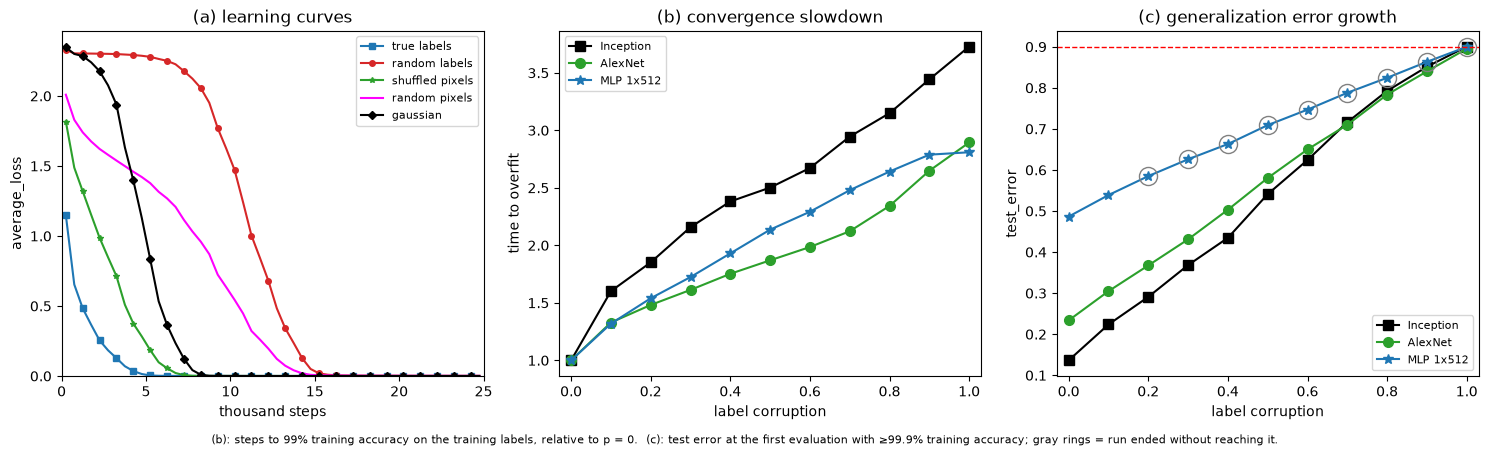

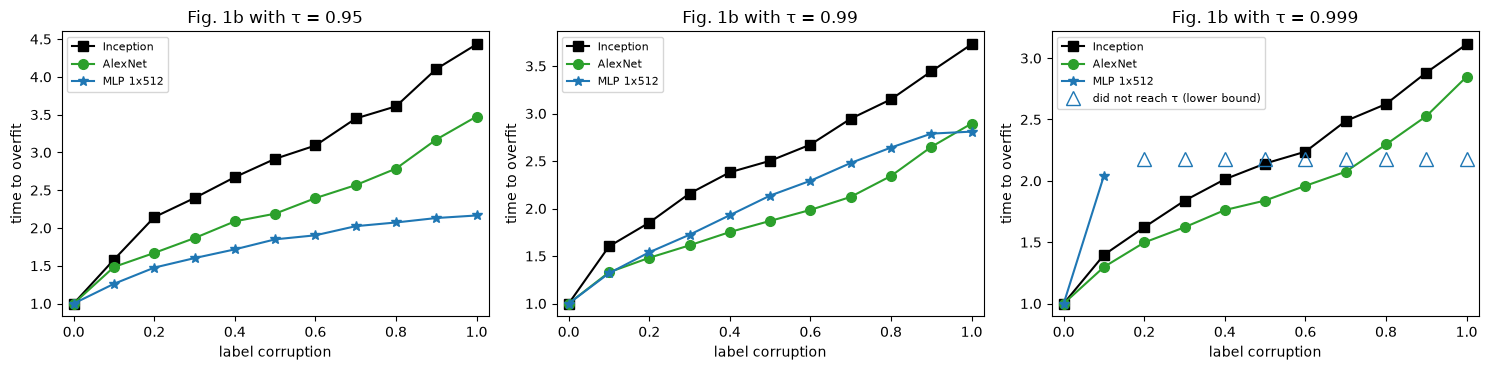

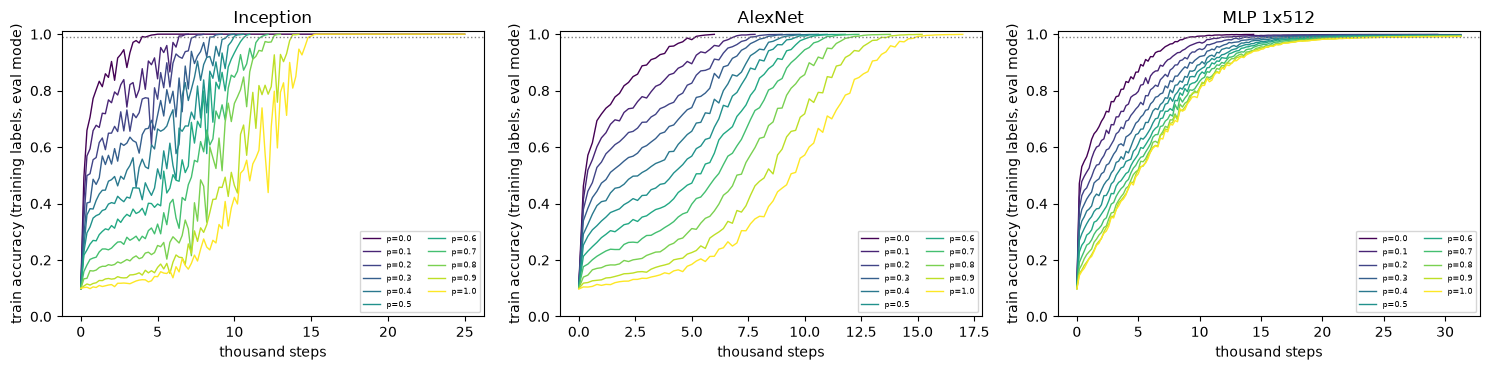

saved: results_fig1\figures\figure1.png, results_fig1\figures\figure1.pdf, and two supplementary figures


In [12]:
fig1a_df, bc_df = make_figures(show=True)
print(f"saved: {FIG_DIR / 'figure1.png'}, {FIG_DIR / 'figure1.pdf'}, and two supplementary figures")

In [13]:
# Per-run summary (all values from the logs)
_cols = ["model", "p", "state", "stop_reason", "frac_labels_changed", f"T_{CONV_TAU}", "eval_step", "train_error", "test_error"]
print(bc_df[[c for c in _cols if c in bc_df.columns]].to_string(index=False))

# Printed (not plotted) comparison with Table 1, rows without random crop / weight decay.
PAPER_TABLE1 = {"inception": {"test_acc_true": 85.75, "train_acc_random": 100.0, "test_acc_random": 9.78},
                "alexnet":   {"test_acc_true": 76.07, "train_acc_random": 99.82, "test_acc_random": 9.86},
                "mlp1x512":  {"test_acc_true": 50.51, "train_acc_random": 99.34, "test_acc_random": 10.61}}
_rows = []
for m in MODELS:
    ev0, ev1 = read_evals(run_dir_for(m, 0.0)), read_evals(run_dir_for(m, 1.0))
    r0 = bc_df[(bc_df.model == m) & (bc_df.p == 0.0)]
    r1 = bc_df[(bc_df.model == m) & (bc_df.p == 1.0)]
    _rows.append({"model": m,
                  "test acc, true labels (ours @ Fig.1c point)": round(100 * (1 - r0.test_error.iloc[0]), 2) if len(r0) and pd.notna(r0.test_error.iloc[0]) else None,
                  "(paper)": PAPER_TABLE1[m]["test_acc_true"],
                  "max train acc, random labels (ours)": round(100 * max(r["train_acc"] for r in ev1), 2) if ev1 else None,
                  "(paper) ": PAPER_TABLE1[m]["train_acc_random"],
                  "test acc, random labels (ours)": round(100 * (1 - r1.test_error.iloc[0]), 2) if len(r1) and pd.notna(r1.test_error.iloc[0]) else None,
                  "(paper)  ": PAPER_TABLE1[m]["test_acc_random"]})
print("\n" + pd.DataFrame(_rows).to_string(index=False))

    model   p state stop_reason  frac_labels_changed       T_0.99  eval_step  train_error  test_error
inception 0.0  done   converged              0.00000  3985.327511       5000      0.00012      0.1364
inception 0.1  done   converged              0.09118  6382.346939       7000      0.00046      0.2237
inception 0.2  done   converged              0.18060  7380.612245       8000      0.00050      0.2909
inception 0.3  done   converged              0.26900  8600.540541       9200      0.00020      0.3683
inception 0.4  done   converged              0.35818  9490.876565      10000      0.00030      0.4347
inception 0.5  done   converged              0.44668  9972.371134      10600      0.00030      0.5410
inception 0.6  done   converged              0.53568 10651.709402      11000      0.00060      0.6242
inception 0.7  done   converged              0.62744 11738.375350      12200      0.00090      0.7162
inception 0.8  done   converged              0.71870 12551.240376      13000      

In [14]:
# ---- 14a. Ablation: setup and runs ----
_needed = ("train_run", "RunConfig", "SmallAlexNet", "glorot_init_", "build_model", "first_crossing", "read_evals",
           "read_json", "write_json", "run_dir_for", "derive_seed", "SEED_INIT", "N_TRAIN", "RESULTS_DIR",
           "STEPS_PER_EPOCH", "BATCH_SIZE", "EVAL_EVERY")
_missing = [n for n in _needed if n not in globals()]
if _missing:
    raise RuntimeError(f"Not defined: {_missing}. Run the notebook from the top (Kernel > Restart & Run All); "
                       "finished main runs are skipped, so this only re-loads the data and definitions.")

from contextlib import contextmanager

ABL_DIR = RESULTS_DIR.with_name(RESULTS_DIR.name + "_ablation_alexnet")   # same folder as the AlexNet-only version
ABL_BUDGET_HOURS = 1.5                    # separate from GPU_BUDGET_HOURS; counts every run in ABL_DIR
ABL_BASE_BATCH = BATCH_SIZE               # the main runs' batch size (read only)
ABL_EXAMPLES_PER_EVAL = EVAL_EVERY * ABL_BASE_BATCH       # 25,600 images, as in the main runs
ABL_PS = (0.0, 1.0)
ABL_MODELS = ("alexnet", "inception")

def _alexnet_no_lrn():
    m = SmallAlexNet()            # constructed exactly like the baseline -> identical RNG draws and initial weights
    m.lrn = nn.Identity()         # removes both LRN layers (they share one parameter-free module)
    return glorot_init_(m)

ABL_VARIANTS = {                  # name: (batch size, model builder; None = the notebook's build_model)
    "bs64":   (64, None),
    "bs256":  (256, None),
    "no_lrn": (ABL_BASE_BATCH, _alexnet_no_lrn),
}
ABL_RUNS = [("alexnet", "bs64"), ("alexnet", "bs256"), ("alexnet", "no_lrn"),      # run order
            ("inception", "bs64"), ("inception", "bs256")]

def _initial_state(builder):      # what make_model_on_device does: seed, then build
    torch.manual_seed(derive_seed(SEED_INIT, SEED))
    return builder().state_dict()
_a, _b = _initial_state(lambda: build_model("alexnet")), _initial_state(_alexnet_no_lrn)
assert _a.keys() == _b.keys() and all(torch.equal(_a[k], _b[k]) for k in _a), "no-LRN init differs from baseline"
print("no_lrn initial weights identical to baseline AlexNet: True")

@contextmanager
def _ablation_settings(batch_size, builder):
    """Point the training engine at one ablation version; restore everything afterwards (also on Ctrl-C / errors)."""
    g = globals()
    saved = {k: g[k] for k in ("BATCH_SIZE", "STEPS_PER_EPOCH", "build_model")}
    flags = (torch.backends.cudnn.benchmark, torch.backends.cudnn.deterministic,
             torch.are_deterministic_algorithms_enabled(), torch.is_deterministic_algorithms_warn_only_enabled())
    try:
        g["BATCH_SIZE"], g["STEPS_PER_EPOCH"] = batch_size, math.ceil(N_TRAIN / batch_size)
        if builder is not None:
            g["build_model"] = lambda name: builder()
        torch.backends.cudnn.benchmark, torch.backends.cudnn.deterministic = True, False   # DETERMINISTIC = False
        torch.use_deterministic_algorithms(False)
        yield
    finally:
        g.update(saved)
        torch.backends.cudnn.benchmark, torch.backends.cudnn.deterministic = flags[0], flags[1]
        torch.use_deterministic_algorithms(flags[2], warn_only=flags[3])

class _AblationBudget:            # the interface train_run expects; time is reconstructed from ABL_DIR
    def __init__(self, hours):
        self.limit_s = hours * 3600.0
        self.used_s = sum(float((read_json(d / "status.json") or {}).get("elapsed_s", 0.0))
                          for d in ABL_DIR.glob("*/*") if d.is_dir())
    def remaining_s(self):
        return self.limit_s - self.used_s

def _abl_cfg(model, batch_size, p):
    return RunConfig(model, p, seed=SEED, data_seed=DATA_SEED, phase=0,
                     eval_every=max(1, round(ABL_EXAMPLES_PER_EVAL / batch_size)))

def _abl_run_dir(model, vname, p):
    return ABL_DIR / vname / _abl_cfg(model, ABL_VARIANTS[vname][0], p).run_id

def run_ablation():
    ABL_DIR.mkdir(parents=True, exist_ok=True)
    write_json(ABL_DIR / "ablation_config.json", {
        "variants": {k: {"batch_size": bs, "lrn_removed": b is not None} for k, (bs, b) in ABL_VARIANTS.items()},
        "runs": [f"{m}/{v}" for m, v in ABL_RUNS], "examples_per_eval": ABL_EXAMPLES_PER_EVAL,
        "deterministic": False, "seed": SEED, "data_seed": DATA_SEED, "baseline": str(RUNS_DIR)})
    budget = _AblationBudget(ABL_BUDGET_HOURS)
    print(f"ablation budget {ABL_BUDGET_HOURS:.2f} h, already used {budget.used_s / 60:.1f} min")
    for model, vname in ABL_RUNS:
        bs, builder = ABL_VARIANTS[vname]
        for p in ABL_PS:
            cfg, rdir = _abl_cfg(model, bs, p), _abl_run_dir(model, vname, p)
            prev = read_json(rdir / "config.json")
            if prev and prev.get("batch_size") != bs:
                raise RuntimeError(f"{rdir} was trained with batch {prev.get('batch_size')}, not {bs}; delete it to rerun")
            if (read_json(rdir / "status.json") or {}).get("state") == "done":
                continue
            if budget.remaining_s() <= 0:
                print("Ablation budget used up; raise ABL_BUDGET_HOURS and re-run this cell to continue.")
                return
            print(f"\n=== ablation {vname}: {model} p={p:.1f}  (batch {bs}, eval every {cfg.eval_every} steps, "
                  f"budget left {budget.remaining_s() / 60:.1f} min) ===")
            with _ablation_settings(bs, builder):
                status = train_run(cfg, budget, runs_root=ABL_DIR / vname)
            if status.get("state") == "paused":
                return
    print(f"\nall ablation runs done; ablation GPU time {_AblationBudget(0).used_s / 60:.1f} min")

run_ablation()

no_lrn initial weights identical to baseline AlexNet: True
ablation budget 1.50 h, already used 0.0 min

=== ablation bs64: alexnet p=0.0  (batch 64, eval every 400 steps, budget left 90.0 min) ===
[alexnet__p0.0__natural__seed0] step   3600  ep   4.6  lr 8.15e-03  train acc 0.8476  loss 0.435  test acc 0.7361    0.4 min
[alexnet__p0.0__natural__seed0] step   7600  ep   9.7  lr 6.30e-03  train acc 0.9802  loss 0.065  test acc 0.7652    0.7 min
[alexnet__p0.0__natural__seed0] step  10400  ep  13.3  lr 5.13e-03  train acc 0.9995  loss 0.004  test acc 0.7749    0.9 min  -> converged

=== ablation bs64: alexnet p=1.0  (batch 64, eval every 400 steps, budget left 89.1 min) ===
[alexnet__p1.0__natural__seed0] step   3600  ep   4.6  lr 8.15e-03  train acc 0.1158  loss 2.299  test acc 0.0839    0.3 min
[alexnet__p1.0__natural__seed0] step   7600  ep   9.7  lr 6.30e-03  train acc 0.1570  loss 2.264  test acc 0.0996    0.6 min
[alexnet__p1.0__natural__seed0] step  11600  ep  14.8  lr 4.88e-03  t

Epoch / LR / summed-LR columns use tau=0.99.  '>=': p=1 never reached tau within the 80-epoch cap (lower bound).  '-': not measurable (p=0 never reached tau, or a run is unfinished).
For reference (not computed here): Fig. 1b read by eye: AlexNet ~1.5x, Inception ~3.6x at p=1.  Table 1 test error at p=0: AlexNet 0.239, Inception 0.143.

    model              version  batch     LRN T(1)/T(0) tau=0.95 T(1)/T(0) tau=0.99 T(1)/T(0) tau=0.999 in summed LR (tau=0.99) test err p=0 T(0) epochs T(1) epochs LR at T(1), % of lr0  complete
  alexnet baseline (main runs)    128     yes               3.48               2.89                2.85                    1.75        0.234        13.2        38.2                 14.2      True
  alexnet                 bs64     64     yes               3.68               2.73                2.66                    1.81        0.225        11.3        30.9                 21.5      True
  alexnet                bs256    256     yes             >=4.79         

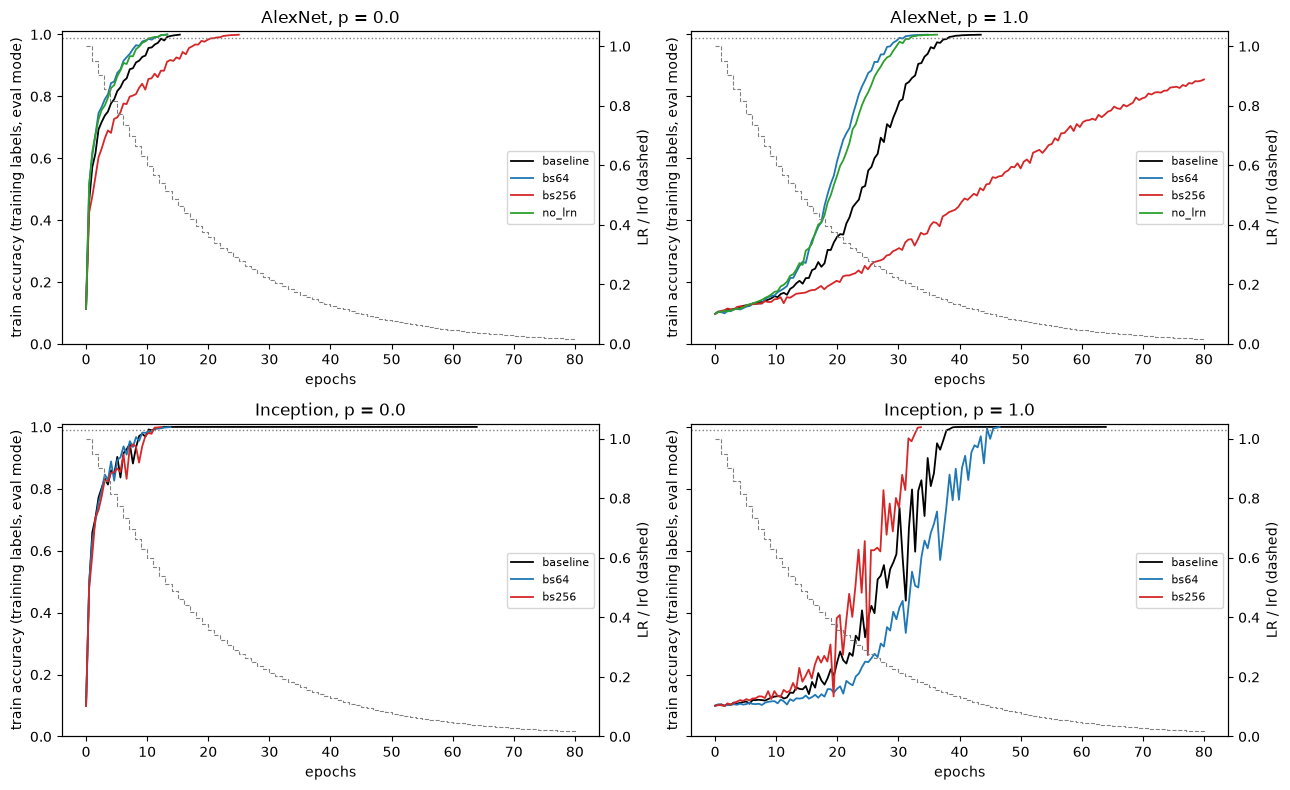

saved results_fig1_ablation_alexnet\summary.csv and results_fig1_ablation_alexnet\ablation_training_curves.png


In [15]:
# ---- 14b. Ablation: table and training curves (everything read from the run logs) ----
def _summed_lr(t, spe):
    """Sum of LR/lr0 over the first t steps under the 0.95-per-epoch staircase (t may be fractional)."""
    e, rem = divmod(t, spe)
    e = int(e)
    return spe * (1 - LR_DECAY_PER_EPOCH ** e) / (1 - LR_DECAY_PER_EPOCH) + rem * LR_DECAY_PER_EPOCH ** e

def _version_summary(model, name, batch_size, lrn, run_dir_of):
    """Same quantities as derive_tables(): tau-crossings (Section 4) and the Fig. 1c test-error point (U14)."""
    row = {"model": model, "version": name, "batch": batch_size, "LRN": lrn}
    runs = {}
    for p in ABL_PS:
        rdir = run_dir_of(p)
        ev = read_evals(rdir)
        st, cf = read_json(rdir / "status.json") or {}, read_json(rdir / "config.json") or {}
        runs[p] = dict(steps=[r["step"] for r in ev], accs=[r["train_acc"] for r in ev], evals=ev,
                       done=st.get("state") == "done", spe=cf.get("steps_per_epoch", math.ceil(N_TRAIN / batch_size)))
    r0, r1 = runs[0.0], runs[1.0]
    for tau in SENS_TAUS:
        t0 = first_crossing(r0["steps"], r0["accs"], tau) if r0["steps"] else None
        t1 = first_crossing(r1["steps"], r1["accs"], tau) if r1["steps"] else None
        row[f"ratio_{tau}"] = t1 / t0 if (t0 and t1) else np.nan
        row[f"ratio_{tau}_lower_bound"] = (r1["steps"][-1] / t0) if (t0 and t1 is None and r1["done"]) else np.nan
        if tau == CONV_TAU:
            row["summed_lr_ratio"] = _summed_lr(t1, r1["spe"]) / _summed_lr(t0, r0["spe"]) if (t0 and t1) else np.nan
            row["T0_epochs"] = t0 / r0["spe"] if t0 else np.nan
            row["T1_epochs"] = t1 / r1["spe"] if t1 else np.nan
            row["lr_at_T1_pct"] = 100 * LR_DECAY_PER_EPOCH ** math.floor(t1 / r1["spe"]) if t1 else np.nan
    k = next((j for j, a in enumerate(r0["accs"]) if a >= STOP_TRAIN_ACC), None)
    if k is None and r0["done"]:
        k = len(r0["evals"]) - 1
    row["test_err_p0"] = 1 - r0["evals"][k]["test_acc"] if k is not None else np.nan
    row["complete"] = r0["done"] and r1["done"]
    return row, runs

_rows, _curves = [], {}
for _m in ABL_MODELS:
    _base_bs = (read_json(run_dir_for(_m, 0.0) / "config.json") or {}).get("batch_size", ABL_BASE_BATCH)
    _row, _curves[(_m, "baseline")] = _version_summary(_m, "baseline (main runs)", _base_bs, "yes" if _m == "alexnet" else "n/a",
                                                       lambda p, m=_m: run_dir_for(m, p))
    _rows.append(_row)
    for _mm, _v in ABL_RUNS:
        if _mm != _m:
            continue
        _bs, _builder = ABL_VARIANTS[_v]
        _lrn = "n/a" if _m != "alexnet" else ("removed" if _builder is not None else "yes")
        _row, _curves[(_m, _v)] = _version_summary(_m, _v, _bs, _lrn, lambda p, m=_m, v=_v: _abl_run_dir(m, v, p))
        _rows.append(_row)
ABL_TABLE = pd.DataFrame(_rows)
ABL_TABLE.to_csv(ABL_DIR / "summary.csv", index=False)

def _fmt_ratio(r, tau):
    if pd.notna(r[f"ratio_{tau}"]):
        return f"{r[f'ratio_{tau}']:.2f}"
    return f">={r[f'ratio_{tau}_lower_bound']:.2f}" if pd.notna(r[f"ratio_{tau}_lower_bound"]) else "-"
_fmt = lambda x, d=1: f"{x:.{d}f}" if pd.notna(x) else "-"
_show = pd.DataFrame({
    "model": ABL_TABLE.model, "version": ABL_TABLE.version, "batch": ABL_TABLE.batch, "LRN": ABL_TABLE.LRN,
    **{f"T(1)/T(0) tau={t}": [_fmt_ratio(r, t) for _, r in ABL_TABLE.iterrows()] for t in SENS_TAUS},
    f"in summed LR (tau={CONV_TAU})": [_fmt(x, 2) for x in ABL_TABLE.summed_lr_ratio],
    "test err p=0": [_fmt(x, 3) for x in ABL_TABLE.test_err_p0],
    "T(0) epochs": [_fmt(x) for x in ABL_TABLE.T0_epochs], "T(1) epochs": [_fmt(x) for x in ABL_TABLE.T1_epochs],
    "LR at T(1), % of lr0": [_fmt(x) for x in ABL_TABLE.lr_at_T1_pct],
    "complete": ABL_TABLE.complete})
print(f"Epoch / LR / summed-LR columns use tau={CONV_TAU}.  '>=': p=1 never reached tau within the 80-epoch cap "
      "(lower bound).  '-': not measurable (p=0 never reached tau, or a run is unfinished).")
print("For reference (not computed here): Fig. 1b read by eye: AlexNet ~1.5x, Inception ~3.6x at p=1.  "
      "Table 1 test error at p=0: AlexNet 0.239, Inception 0.143.\n")
print(_show.to_string(index=False))
if not ABL_TABLE.complete.all():
    print("\nSome versions are incomplete (runs paused or not started); their numbers are partial.")

fig, axes = plt.subplots(len(ABL_MODELS), 2, figsize=(13, 4 * len(ABL_MODELS)), sharey=True, squeeze=False)
_colors = {"baseline": "black", "bs64": "tab:blue", "bs256": "tab:red", "no_lrn": "tab:green"}
for i, m in enumerate(ABL_MODELS):
    for j, p in enumerate(ABL_PS):
        ax = axes[i, j]
        for (mm, v), runs in _curves.items():
            r = runs[p]
            if mm == m and r["steps"]:
                ax.plot(np.array(r["steps"]) / r["spe"], r["accs"], color=_colors.get(v), lw=1.3, label=v)
        ax.axhline(CONV_TAU, color="gray", ls=":", lw=1)
        lr_ax = ax.twinx()
        _e = np.arange(MAX_EPOCHS + 1)
        lr_ax.step(_e, LR_DECAY_PER_EPOCH ** _e, where="post", color="gray", lw=0.8, ls="--")
        lr_ax.set(ylim=(0, 1.05), ylabel="LR / lr0 (dashed)")
        ax.set(title=f"{MODEL_LABEL[m]}, p = {p:.1f}", xlabel="epochs",
               ylabel="train accuracy (training labels, eval mode)", ylim=(0, 1.01))
        if ax.get_lines():
            ax.legend(fontsize=8, loc="center right")
fig.tight_layout()
fig.savefig(ABL_DIR / "ablation_training_curves.png", dpi=130, bbox_inches="tight")
plt.show()
print(f"saved {ABL_DIR / 'summary.csv'} and {ABL_DIR / 'ablation_training_curves.png'}")